# Funnel and cohorts - Google Merchandise Store (GA4)

Each section runs a query from `sql/`. Results are cached in `data/`; without the cache, queries run on BigQuery (`gcloud auth application-default login`). To re-run a query after changing its `.sql`, delete its CSV.

In [4]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from google.cloud import bigquery

SQL_DIR = Path("../sql")
DATA_DIR = Path("../data")


def run_sql(name):
    """Run sql/<name>.sql on BigQuery. The result is cached in data/<name>.csv to save quota.

    If the .sql changes, delete its CSV so the query runs again.
    """
    cache = DATA_DIR / f"{name}.csv"
    if cache.exists():
        return pd.read_csv(cache)
    query = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    df = bigquery.Client().query(query).to_dataframe()
    df.to_csv(cache, index=False)
    return df

## Daily users

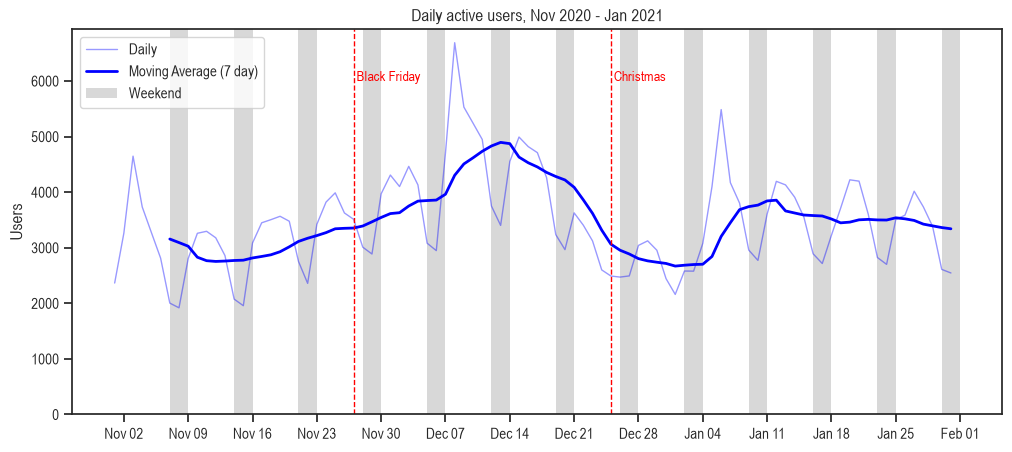

In [5]:
# Load the data
df = run_sql("01_daily_users")
df["event_day"] = pd.to_datetime(df["event_day"])

# Calculate moving average
df["moving_average"] = df["users"].rolling(7).mean()

# Graph settings
sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(12, 5))

# Base line graph
sns.lineplot(data=df, x="event_day", y='users', ax=ax, color="blue", alpha=0.4, linewidth=1, label="Daily")
sns.lineplot(data=df, x="event_day", y='moving_average', ax=ax, color="blue", alpha=1, linewidth=2, label="Moving Average (7 day)")

# Show holidays
ax.axvline(pd.Timestamp("2020-11-27"), color="red", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2020-11-27"), 6000, " Black Friday", color="red", fontsize=10)
ax.axvline(pd.Timestamp("2020-12-25"), color="red", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2020-12-25"), 6000, " Christmas", color="red", fontsize=10)

# Mark weekends
saturdays = df.loc[df["event_day"].dt.dayofweek == 5, "event_day"]
for i, sat in enumerate(saturdays):
  ax.axvspan(sat, sat+ pd.Timedelta(days=2), color="gray", alpha=0.3, linewidth=0, label="Weekend" if i == 0 else None)

# Ticks on mondays
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

# Labels
ax.set_title("Daily active users, Nov 2020 - Jan 2021")
ax.set_xlabel(None)
ax.set_ylabel("Users")
ax.set_ylim(bottom=0)
ax.legend()

plt.savefig("../img/01_daily_users.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

- Activity peaks in the first two weeks of December, with ~4,900 daily users (7-day avg) vs ~2,800 in early November.
- Weekends have ~30% fewer users than weekdays.
- Black Friday doesn't seem to affect activity.
- Activity drops from Dec 18 and bottoms out at ~2,700 daily users between Christmas and New Year.
- Activity recovers in the week after New Year: from ~2,700 to ~3,850 daily users (7-day avg) between Jan 4 and Jan 11. It then stays around ~3,500, higher than in November.

## Device, country and channel

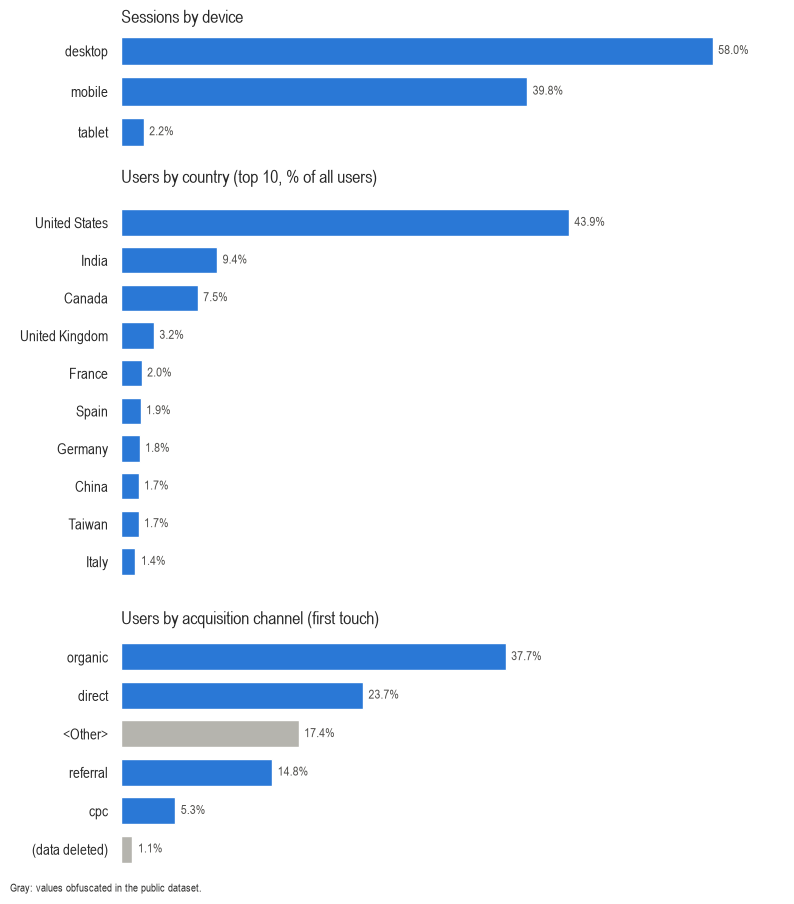

In [6]:
device = run_sql("02_sessions_by_device")
country = run_sql("03_users_by_country")
channel = run_sql("04_users_by_channel")

# (none) is direct traffic in GA4
channel["channel"] = channel["channel"].replace({"(none)": "direct"})

BLUE = "#2a78d6"
GRAY = "#b5b4ae"  # obfuscated values, not real channels
OBFUSCATED = ["<Other>", "(data deleted)"]

panels = [
    (device, "device", "pct_sessions", "Sessions by device"),
    (country, "country", "pct_users", "Users by country (top 10, % of all users)"),
    (channel, "channel", "pct_users", "Users by acquisition channel (first touch)"),
]

# Height proportional to the number of bars, so all bars have the same thickness
fig, axes = plt.subplots(
    3, 1, figsize=(8, 9), sharex=True,
    gridspec_kw={"height_ratios": [len(d) for d, *_ in panels]},
)

for ax, (data, label, value, title) in zip(axes, panels):
    colors = [GRAY if c in OBFUSCATED else BLUE for c in data[label]]
    ax.barh(data[label], data[value], color=colors, height=0.7)
    ax.invert_yaxis()
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4, fontsize=9, color="#52514e")
    ax.set_title(title, loc="left", fontsize=13)
    ax.tick_params(left=False, bottom=False, labelbottom=False)
    sns.despine(ax=ax, left=True, bottom=True)

axes[0].set_xlim(0, 65)
fig.text(0.01, 0.0, "Gray: values obfuscated in the public dataset.", fontsize=8, color="#2c2c2b")
fig.tight_layout()

plt.savefig("../img/02_breakdowns.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

- **Device:** desktop drives 58% of sessions, mobile 40% and tablet 2%.
- **Country:** the US accounts for 44% of users, over 4x India (9%). The top 3 countries (US, India, Canada) make up 61% and the top 10 make up 74%.
- **Channel:** organic search brings 38% of users, direct traffic 24% and referrals 15%. Paid search (cpc) brings only 5%. 18% of users have an obfuscated medium, so channel shares are approximate.
- 15% of users appear with more than one medium. Each user is assigned the medium of their first event (first-touch attribution). Without this, referral looked bigger (17% vs 15%).

**Questions for the funnel:**  Does conversion differ by country? India is #2 in traffic, so a low rate there would matter most. Does mobile convert less than desktop?